# Stage 7: Model Evaluation and Comparison
## Hospital Resource Intelligence and Optimization Platform

This notebook compiles, visualizes, and evaluates the performance of the three models (Prophet, XGBoost, LSTM) trained to forecast daily hospital resource demand for the next **7 days**.

The comparison includes:
1. **Comparability Check**: Confirming that all models were tested on the exact same date windows and actual values.
2. **Metric Summary Table**: Comparing MAE, RMSE, and MAPE scores.
3. **Ranking Matrix**: Ranking models by MAE and RMSE separately.
4. **Error Analysis**: Tracking absolute error ranges (min, max, std) and date-specific error concentrations.
5. **Visual Comparison**: Bar charts of MAE/RMSE scores, prediction curves overlay, and error distributions.

In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set styles
sns.set_theme(style='whitegrid')
INTERIM_DIR = '../data/interim'
EVAL_DIR = '../ml/evaluation'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. Metrics Consolidation
We load the consolidated metrics table generated by the comparison script.

In [2]:
df_compare = pd.read_csv(os.path.join(EVAL_DIR, 'model_comparison.csv'))
print('Consolidated Comparison Data:')
df_compare

Consolidated Comparison Data:


,target,model,mae,rmse,mape,min_abs_error,max_abs_error,std_abs_error,mae_rank,rmse_rank
0,icu_occupancy,Prophet,0.619799,0.633932,0.672041,0.306348,0.733033,0.133115,2,2
1,icu_occupancy,XGBoost,0.594035,0.619172,0.659030,0.204068,0.762975,0.174632,1,1
2,icu_occupancy,LSTM,0.716405,0.747726,0.803660,0.192877,0.829890,0.214143,3,3
3,ed_arrivals,Prophet,0.317040,0.504245,0.934690,0.009564,0.953487,0.392108,3,2
4,ed_arrivals,XGBoost,0.289079,0.529347,0.990181,0.000000,0.994914,0.443442,1,3
5,ed_arrivals,LSTM,0.304921,0.504220,0.939598,0.024375,0.944526,0.401573,2,1


## 2. Comparative Visualizations (MAE & RMSE)
We plot bar charts comparing MAE and RMSE scores across all models for both targets.

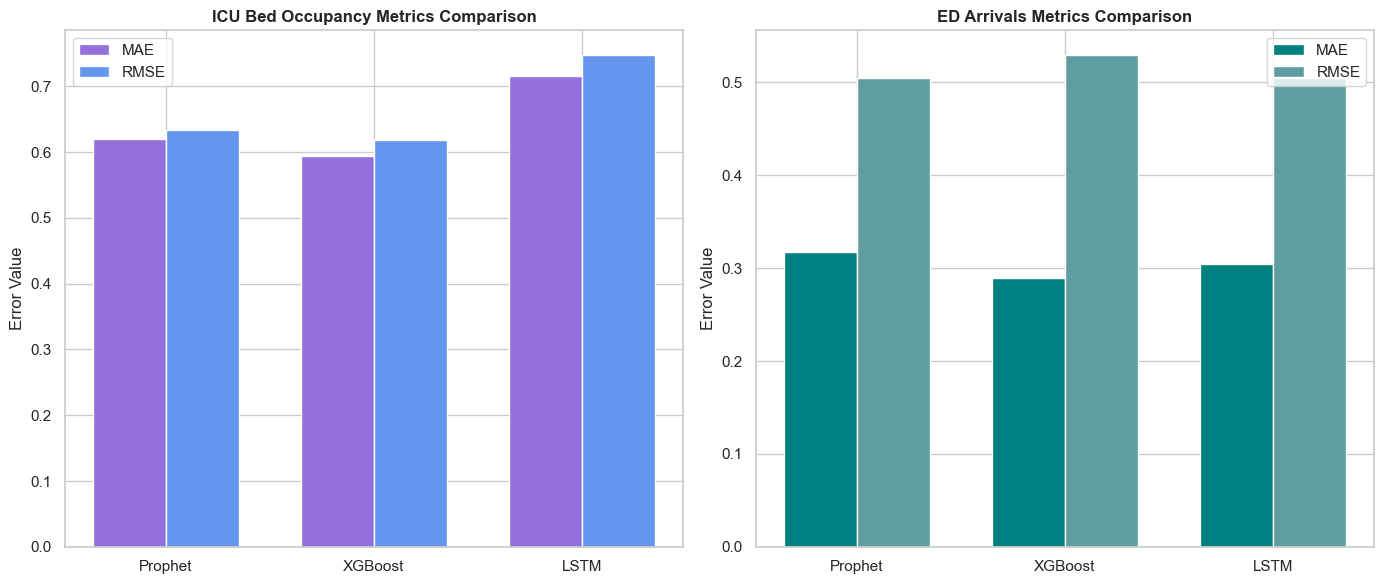

In [3]:
# Plot MAE and RMSE comparison side-by-side
plt.figure(figsize=(14, 6))

# ICU Beds
df_icu = df_compare[df_compare['target'] == 'icu_occupancy']
plt.subplot(1, 2, 1)
x = np.arange(len(df_icu['model']))
width = 0.35
plt.bar(x - width/2, df_icu['mae'], width, label='MAE', color='mediumpurple')
plt.bar(x + width/2, df_icu['rmse'], width, label='RMSE', color='cornflowerblue')
plt.xticks(x, df_icu['model'])
plt.title('ICU Bed Occupancy Metrics Comparison', fontsize=12, fontweight='bold')
plt.ylabel('Error Value')
plt.legend()

# ED Arrivals
df_ed = df_compare[df_compare['target'] == 'ed_arrivals']
plt.subplot(1, 2, 2)
x_ed = np.arange(len(df_ed['model']))
plt.bar(x_ed - width/2, df_ed['mae'], width, label='MAE', color='teal')
plt.bar(x_ed + width/2, df_ed['rmse'], width, label='RMSE', color='cadetblue')
plt.xticks(x_ed, df_ed['model'])
plt.title('ED Arrivals Metrics Comparison', fontsize=12, fontweight='bold')
plt.ylabel('Error Value')
plt.legend()

plt.tight_layout()
plt.show()

## 3. Forecasting Curves Overlay (Actual vs Predicted)
We plot the actual test counts alongside the predictions of all three models on the same timeline to inspect the forecasting alignment.

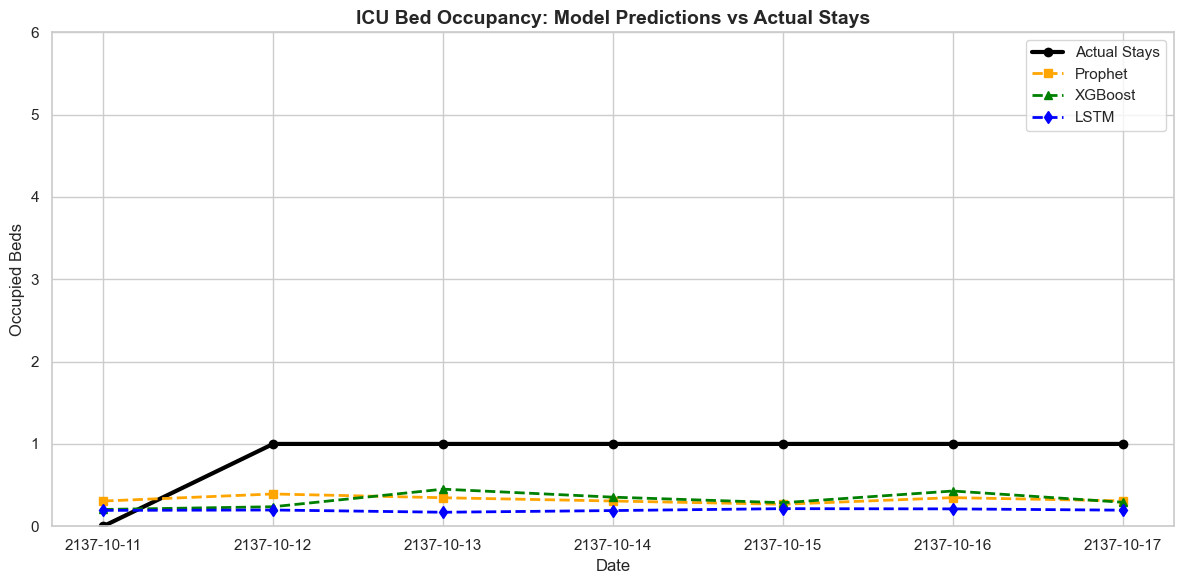

In [4]:
# Load predictions
df_p_icu = pd.read_csv(os.path.join(INTERIM_DIR, 'prophet_icu_forecast.csv'))
df_x_icu = pd.read_csv(os.path.join(INTERIM_DIR, 'xgboost_icu_forecast.csv'))
df_l_icu = pd.read_csv(os.path.join(INTERIM_DIR, 'lstm_icu_forecast.csv'))

df_p_icu['date'] = pd.to_datetime(df_p_icu['date'])
df_x_icu['date'] = pd.to_datetime(df_x_icu['date'])
df_l_icu['date'] = pd.to_datetime(df_l_icu['date'])

plt.figure(figsize=(12, 6))
plt.plot(df_p_icu['date'], df_p_icu['actual'], label='Actual Stays', color='black', marker='o', linewidth=3)
plt.plot(df_p_icu['date'], df_p_icu['predicted'], label='Prophet', color='orange', marker='s', linestyle='--', linewidth=2)
plt.plot(df_x_icu['date'], df_x_icu['predicted'], label='XGBoost', color='green', marker='^', linestyle='--', linewidth=2)
plt.plot(df_l_icu['date'], df_l_icu['predicted'], label='LSTM', color='blue', marker='d', linestyle='--', linewidth=2)
plt.title('ICU Bed Occupancy: Model Predictions vs Actual Stays', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Occupied Beds')
plt.ylim(0, 6)
plt.legend()
plt.tight_layout()
plt.show()

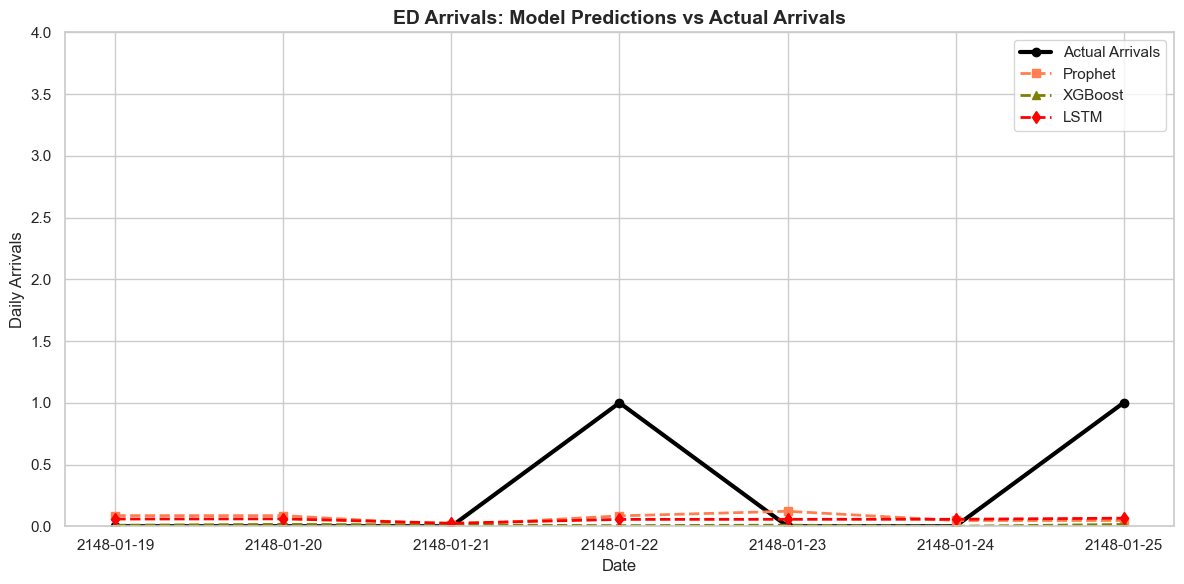

In [5]:
df_p_ed = pd.read_csv(os.path.join(INTERIM_DIR, 'prophet_ed_forecast.csv'))
df_x_ed = pd.read_csv(os.path.join(INTERIM_DIR, 'xgboost_ed_forecast.csv'))
df_l_ed = pd.read_csv(os.path.join(INTERIM_DIR, 'lstm_ed_forecast.csv'))

df_p_ed['date'] = pd.to_datetime(df_p_ed['date'])
df_x_ed['date'] = pd.to_datetime(df_x_ed['date'])
df_l_ed['date'] = pd.to_datetime(df_l_ed['date'])

plt.figure(figsize=(12, 6))
plt.plot(df_p_ed['date'], df_p_ed['actual'], label='Actual Arrivals', color='black', marker='o', linewidth=3)
plt.plot(df_p_ed['date'], df_p_ed['predicted'], label='Prophet', color='coral', marker='s', linestyle='--', linewidth=2)
plt.plot(df_x_ed['date'], df_x_ed['predicted'], label='XGBoost', color='olive', marker='^', linestyle='--', linewidth=2)
plt.plot(df_l_ed['date'], df_l_ed['predicted'], label='LSTM', color='red', marker='d', linestyle='--', linewidth=2)
plt.title('ED Arrivals: Model Predictions vs Actual Arrivals', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Daily Arrivals')
plt.ylim(0, 4)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Absolute Error Analysis
We plot the absolute errors of each model over the 7 forecast days to see if error accumulates on later forecast steps.

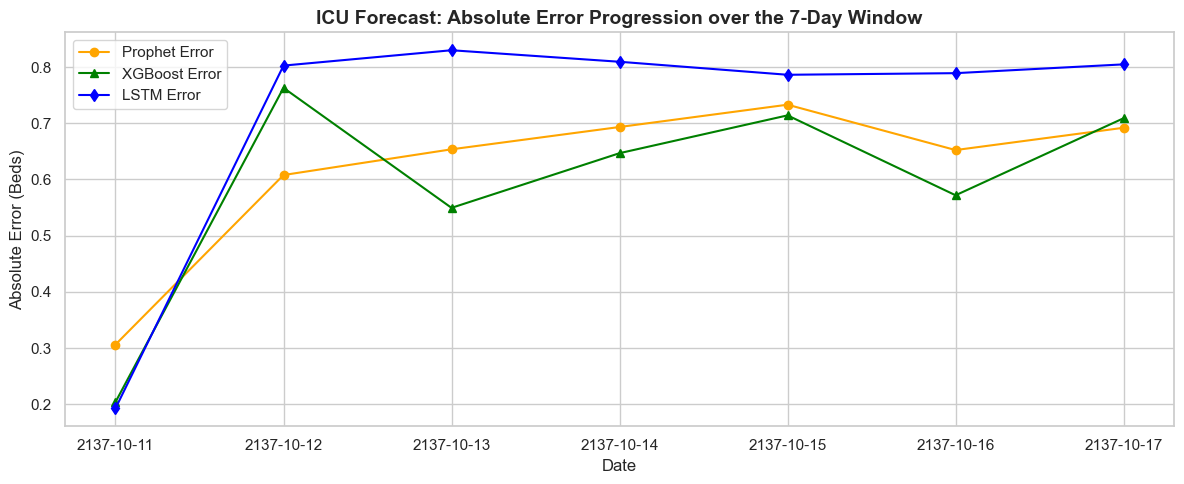

In [6]:
# Compute absolute errors
df_err_icu = pd.DataFrame({
    'date': df_p_icu['date'],
    'Prophet': np.abs(df_p_icu['actual'] - df_p_icu['predicted']),
    'XGBoost': np.abs(df_x_icu['actual'] - df_x_icu['predicted']),
    'LSTM': np.abs(df_l_icu['actual'] - df_l_icu['predicted'])
})

plt.figure(figsize=(12, 5))
plt.plot(df_err_icu['date'], df_err_icu['Prophet'], label='Prophet Error', color='orange', marker='o', linestyle='-')
plt.plot(df_err_icu['date'], df_err_icu['XGBoost'], label='XGBoost Error', color='green', marker='^', linestyle='-')
plt.plot(df_err_icu['date'], df_err_icu['LSTM'], label='LSTM Error', color='blue', marker='d', linestyle='-')
plt.title('ICU Forecast: Absolute Error Progression over the 7-Day Window', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Absolute Error (Beds)')
plt.legend()
plt.tight_layout()
plt.show()

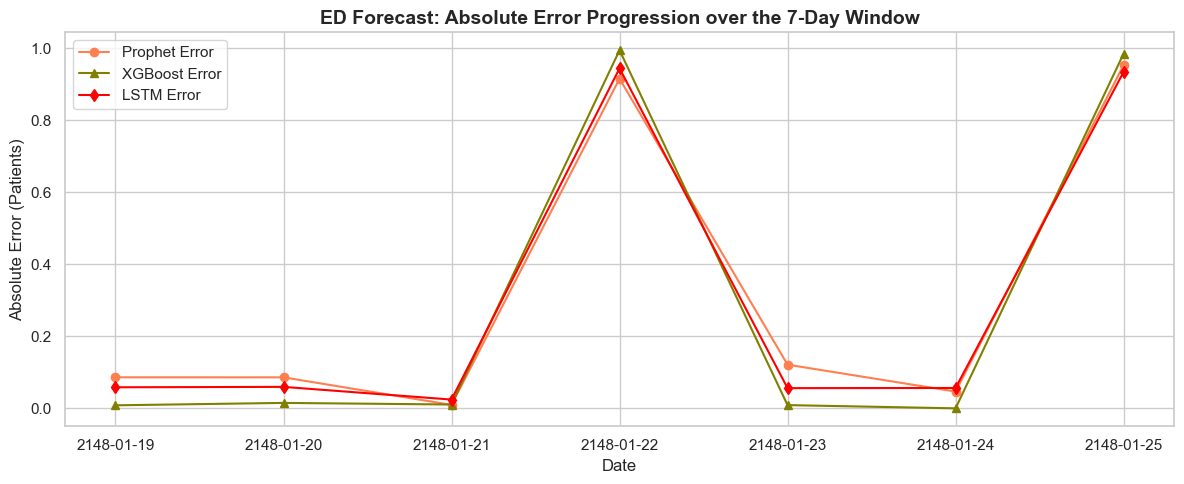

In [7]:
df_err_ed = pd.DataFrame({
    'date': df_p_ed['date'],
    'Prophet': np.abs(df_p_ed['actual'] - df_p_ed['predicted']),
    'XGBoost': np.abs(df_x_ed['actual'] - df_x_ed['predicted']),
    'LSTM': np.abs(df_l_ed['actual'] - df_l_ed['predicted'])
})

plt.figure(figsize=(12, 5))
plt.plot(df_err_ed['date'], df_err_ed['Prophet'], label='Prophet Error', color='coral', marker='o', linestyle='-')
plt.plot(df_err_ed['date'], df_err_ed['XGBoost'], label='XGBoost Error', color='olive', marker='^', linestyle='-')
plt.plot(df_err_ed['date'], df_err_ed['LSTM'], label='LSTM Error', color='red', marker='d', linestyle='-')
plt.title('ED Forecast: Absolute Error Progression over the 7-Day Window', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Absolute Error (Patients)')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Statistical Error Summary
We show the descriptive stats of absolute error ranges (min, max, std) for each model.

In [8]:
print('ICU Bed Occupancy Absolute Error Ranges:')
print(df_err_icu.describe().T[['min', 'max', 'std', 'mean']])
print('\nED Arrivals Absolute Error Ranges:')
print(df_err_ed.describe().T[['min', 'max', 'std', 'mean']])

ICU Bed Occupancy Absolute Error Ranges:
                         min                  max       std  \
date     2137-10-11 00:00:00  2137-10-17 00:00:00       NaN   
Prophet             0.306348             0.733033  0.143781   
XGBoost             0.204068             0.762975  0.188624   
LSTM                0.192877              0.82989  0.231301   

                        mean  
date     2137-10-14 00:00:00  
Prophet             0.619799  
XGBoost             0.594035  
LSTM                0.716405  

ED Arrivals Absolute Error Ranges:
                         min                  max       std  \
date     2148-01-19 00:00:00  2148-01-25 00:00:00       NaN   
Prophet             0.009564             0.953487  0.423525   
XGBoost                  0.0             0.994914  0.478972   
LSTM                0.024375             0.944526  0.433749   

                        mean  
date     2148-01-22 00:00:00  
Prophet              0.31704  
XGBoost             0.289079  
LSTM        